# Rapalog Discovery Pipeline
## 06 Binding Affinity Prediction

This notebook combines:
- **Phase 6**: chemistry + similarity feature-space analysis
- **Phase 7**: binding-affinity regression modeling

Phase 6 and Phase 7 are combined because the feature space generated in Phase 6 is directly used by the regression models in Phase 7.

Workflow:
1. Load Phase 5 docking results (`docking_results_full.csv`)
2. Prepare Phase 6/7 dataset artifacts using `src.binding_model`
3. Run PCA + clustering diagnostics
4. Train baseline + regularized linear models
5. Compare model performance
6. Review feature importance and subgroup error behavior

## How to run this notebook
### Configuration scenarios in <code>config.py</code>
| Scenario | Key flags | What it does |
|---|---|---|
| First-time build (debug) | `DOCKING_RUN_MODE="debug"`, `BINDING_TEST_SIZE=0.20`, `BINDING_P6_K_RANGE=range(2,15)` | Loads debug docking results from Notebook 05, builds Phase 6/7 artifacts, trains all models, and saves plots/tables to `results/notebook_06/debug/`. |
| First-time build (production) | `DOCKING_RUN_MODE="production"`, `BINDING_TEST_SIZE=0.20`, `BINDING_P6_K_RANGE=range(2,15)` | Loads production docking results from Notebook 05 and runs full Phase 6/7 outputs to `results/notebook_06/prod/`. |
| Faster split iteration | `BINDING_TEST_SIZE=0.10` (or other value), `RANDOM_STATE=<fixed int>` | Quickly reruns train/test experiments while keeping reproducibility controlled by `RANDOM_STATE`. |
| Regularization sweep tuning | `BINDING_P7_ALPHA_LOGSPACE_START`, `BINDING_P7_ALPHA_LOGSPACE_STOP`, `BINDING_P7_ALPHA_LOGSPACE_NUM`, `BINDING_P7_ELASTIC_L1_RATIOS` | Changes ElasticNet/Ridge/Lasso CV search space without editing notebook code. |
| PCA/K diagnostics tuning | `BINDING_P6_PCA_CUMVAR_THRESHOLD`, `BINDING_P6_K_RANGE` | Adjusts displayed PCA variance threshold and KMeans elbow/silhouette range. |

### Parameters used directly in this notebook
| Parameter | Used for |
|---|---|
| `DOCKING_RUN_MODE` | Selects debug/production results paths and output folder suffix (`debug`/`prod`). |
| `BINDING_TARGET_COL` | Defines supervised target column passed into Phase 6/7 dataset preparation. |
| `BINDING_SIMILARITY_COL` | Defines similarity feature column used for Phase 6/7 modeling and residual plotting. |
| `BINDING_TEST_SIZE` | Sets stratified holdout fraction for Phase 7 train/test split. |
| `RANDOM_STATE` | Controls reproducibility for dataset prep and regularized model CV. |
| `BINDING_P6_PCA_CUMVAR_THRESHOLD` | Draws PCA cumulative-variance reference line in Phase 6 diagnostics. |
| `BINDING_P6_K_RANGE` | Controls evaluated `k` values for elbow and silhouette diagnostics. |
| `BINDING_P7_ALPHA_LOGSPACE_START` | Lower log10 bound for regularization alpha grid. |
| `BINDING_P7_ALPHA_LOGSPACE_STOP` | Upper log10 bound for regularization alpha grid. |
| `BINDING_P6_UMAP_N_NEIGHBORS` | Controls the UMAP neighborhood size for Phase 6 embedding. |
| `BINDING_P6_UMAP_MIN_DIST` | Controls UMAP minimum distance for Phase 6 embedding. |
| `BINDING_P7_ALPHA_LOGSPACE_NUM` | Number of alpha values in regularization grid. |
| `BINDING_P7_ELASTIC_L1_RATIOS` | Candidate Elastic Net L1/L2 mixtures for cross-validation. |

In [12]:
# P6/P7 setup: imports, paths, and data load
import sys
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import config
config = importlib.reload(config)

import src.binding_model as binding_model
import src.clustering as clustering

binding_model = importlib.reload(binding_model)
clustering = importlib.reload(clustering)

from src.binding_model import (
    prepare_binding_dataset,
    train_baseline_regression,
    train_elastic_net,
    train_ridge,
    train_lasso,
    compare_models,
    plot_feature_importance,
    error_analysis,
)
from src.clustering import evaluate_k

run_mode = str(getattr(config, "DOCKING_RUN_MODE", "debug")).strip().lower()
if run_mode not in {"debug", "production"}:
    raise ValueError("DOCKING_RUN_MODE must be 'debug' or 'production'.")

mode_suffix = "debug" if run_mode == "debug" else "prod"
results_dir = PROJECT_ROOT / "results" / "notebook_06" / mode_suffix
results_dir.mkdir(parents=True, exist_ok=True)
plots_dir = results_dir / "plots"
plots_dir.mkdir(parents=True, exist_ok=True)

phase5_results_csv = PROJECT_ROOT / "results" / "notebook_05" / mode_suffix / "docking_results_full.csv"
if not phase5_results_csv.exists():
    raise FileNotFoundError(f"Missing docking results file: {phase5_results_csv}")

docking_full_df = pd.read_csv(phase5_results_csv)
print("Project root:", PROJECT_ROOT)
print("Run mode:", run_mode)
print("Loaded docking results:", phase5_results_csv)
print("Docking dataframe shape:", docking_full_df.shape)
print("Results dir:", results_dir)
print("Plots dir:", plots_dir)
display(docking_full_df.head())

Project root: /Users/alangale/Projects/rapalog-discovery-pipeline
Run mode: debug
Loaded docking results: /Users/alangale/Projects/rapalog-discovery-pipeline/results/notebook_05/debug/docking_results_full.csv
Docking dataframe shape: (21, 14)
Results dir: /Users/alangale/Projects/rapalog-discovery-pipeline/results/notebook_06/debug
Plots dir: /Users/alangale/Projects/rapalog-discovery-pipeline/results/notebook_06/debug/plots


,name,vina_score,smiles,hbd,hba,rings,aromatic_rings,tpsa,logp,mw,amide,sim_r1_tv_frag,cluster_k2,quartile
0,CNP0253821.1,-9.150,O=C1OC2=CC=CC=C2C(=O)/C1=C\NC1=CC=C(C2=CC3=CC=...,1,6,5,4,85.61,4.55770,409.397,0,0.190476,0,3
1,NCGC00393416-01,-8.656,O=C(NC[C@H]1CN2C(C3=CC=CC(Cl)=C3)=CN=C2CO1)NC1...,2,3,4,3,68.18,3.92400,382.851,2,0.168776,0,3
2,"5,8-dihydroxy-2-(5-hydroxy-7-methyl-1,4-dioxon...",-8.617,CC1=C(C2=CC(=O)C3=C(O)C=C(C)C=C3C2=O)C(=O)C2=C...,3,7,4,2,128.97,2.81292,390.347,0,0.289855,1,1
3,NPD7170,-8.580,CC1=C(CC(=O)NCCC2=CN=CN2)C(=O)OC2=C(C)C3=C(C=C...,2,5,5,5,101.13,4.44754,441.487,1,0.219298,0,2
4,3-[4-(4-methoxyphenoxy)pyrimidin-2-yl]-N-[(3-m...,-8.526,COC1=CC=C(OC2=CC=NC(C3=CC=CC(C(=O)NCC4=CC=CC(O...,1,6,4,4,82.57,4.88310,441.487,1,0.208333,0,3


In [13]:
# P6.A-P6.C Build chemistry+similarity feature space and PCA artifacts
binding_artifacts = prepare_binding_dataset(
    docking_full_df,
    target_col=config.BINDING_TARGET_COL,
    similarity_col=config.BINDING_SIMILARITY_COL,
    test_size=config.BINDING_TEST_SIZE,
    random_state=config.RANDOM_STATE,
)

phase6_df = binding_artifacts["phase6_df"]
X_chemsim_features = binding_artifacts["X_chemsim_features"]
X_chemsim_scaled = binding_artifacts["X_chemsim_scaled"]
loadings_chemsim = binding_artifacts["loadings_chemsim"]
explained_var_chemsim = binding_artifacts["explained_var_chemsim"]

print("Phase 6 rows:", len(phase6_df))
print("Phase 7 train/test:", binding_artifacts["train_df"].shape, binding_artifacts["test_df"].shape)
print("PCA variance explained (PC1, PC2):", explained_var_chemsim[:2])

display(loadings_chemsim)
display(phase6_df.head())

Phase 6 rows: 21
Phase 7 train/test: (14, 15) (7, 15)
PCA variance explained (PC1, PC2): [0.30276895 0.2678117 ]


,PC1,PC2
hbd,0.342640,-0.012864
hba,0.450930,0.050632
rings,0.023612,0.466573
aromatic_rings,-0.135813,0.552579
tpsa,0.569736,0.062042
logp,-0.373948,0.195122
mw,0.404305,0.279789
amide,0.116507,0.327666
similarity,0.137058,-0.496658


,name,vina_score,smiles,hbd,hba,rings,aromatic_rings,tpsa,logp,mw,amide,sim_r1_tv_frag,cluster_k2,quartile,original_index,PC1,PC2,cluster_k2_phase6,cluster_k4_phase6
0,CNP0253821.1,-9.150,O=C1OC2=CC=CC=C2C(=O)/C1=C\NC1=CC=C(C2=CC3=CC=...,1,6,5,4,85.61,4.55770,409.397,0,0.190476,0,3,0,-1.232123,2.154273,0,1
1,NCGC00393416-01,-8.656,O=C(NC[C@H]1CN2C(C3=CC=CC(Cl)=C3)=CN=C2CO1)NC1...,2,3,4,3,68.18,3.92400,382.851,2,0.168776,0,3,1,-1.933418,1.593927,0,3
2,"5,8-dihydroxy-2-(5-hydroxy-7-methyl-1,4-dioxon...",-8.617,CC1=C(C2=CC(=O)C3=C(O)C=C(C)C=C3C2=O)C(=O)C2=C...,3,7,4,2,128.97,2.81292,390.347,0,0.289855,1,1,2,1.945750,-0.542541,1,0
3,NPD7170,-8.580,CC1=C(CC(=O)NCCC2=CN=CN2)C(=O)OC2=C(C)C3=C(C=C...,2,5,5,5,101.13,4.44754,441.487,1,0.219298,0,2,3,-0.389872,2.714698,0,1
4,3-[4-(4-methoxyphenoxy)pyrimidin-2-yl]-N-[(3-m...,-8.526,COC1=CC=C(OC2=CC=NC(C3=CC=CC(C(=O)NCC4=CC=CC(O...,1,6,4,4,82.57,4.88310,441.487,1,0.208333,0,3,4,-1.062039,1.987645,0,1


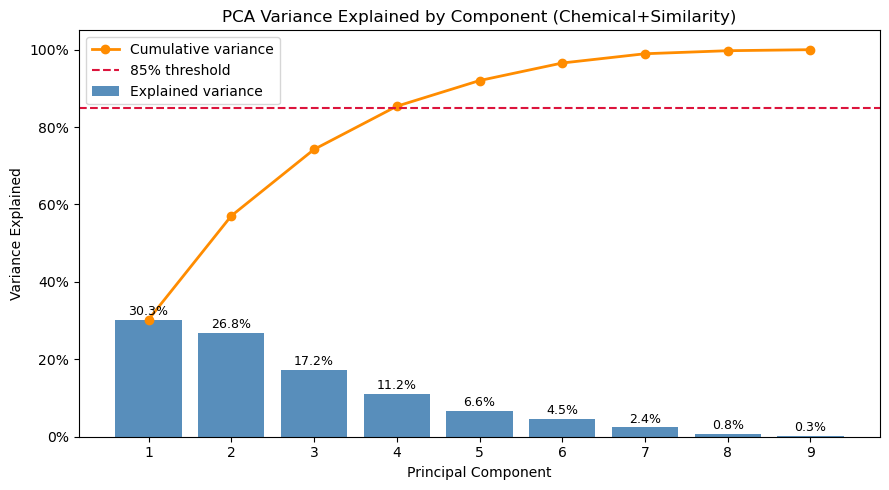

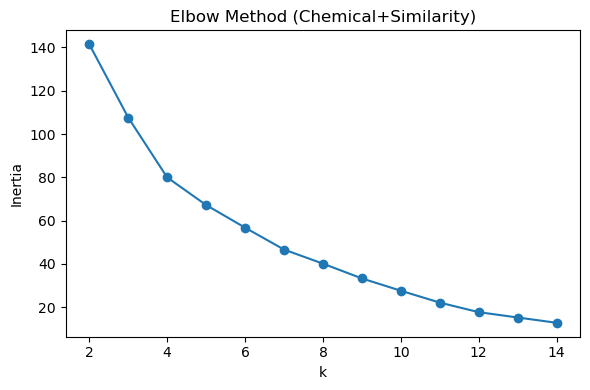

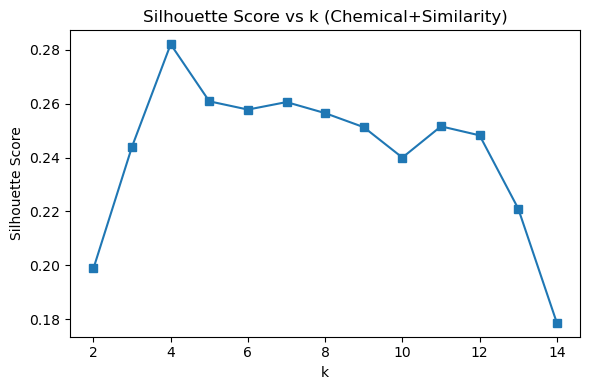

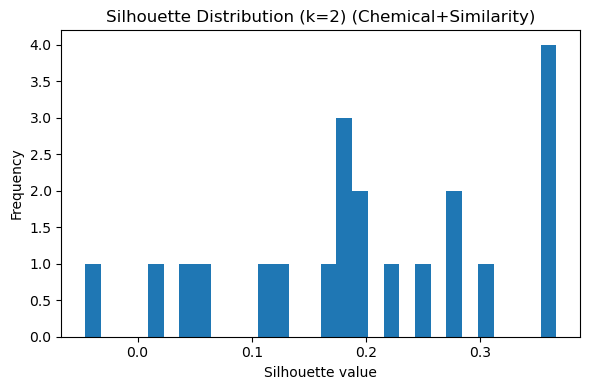

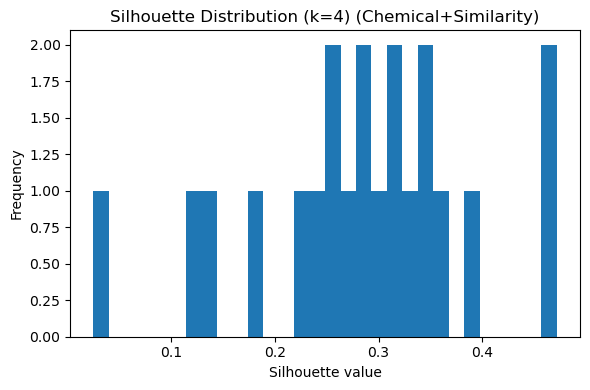

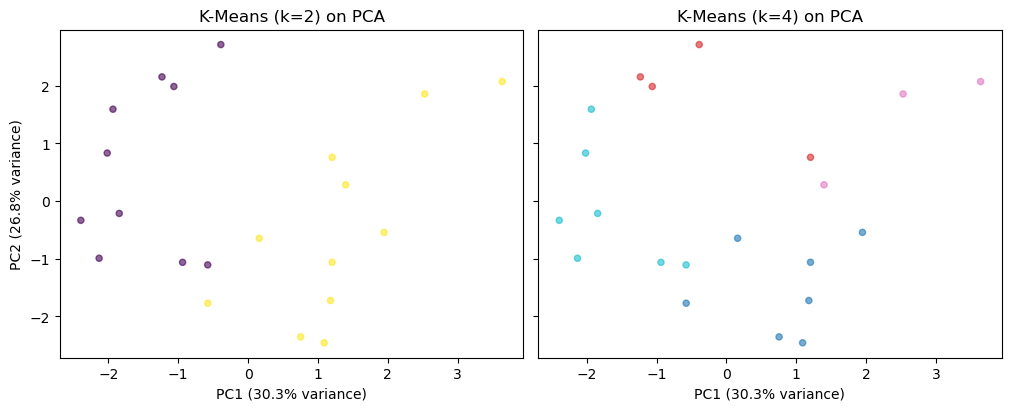

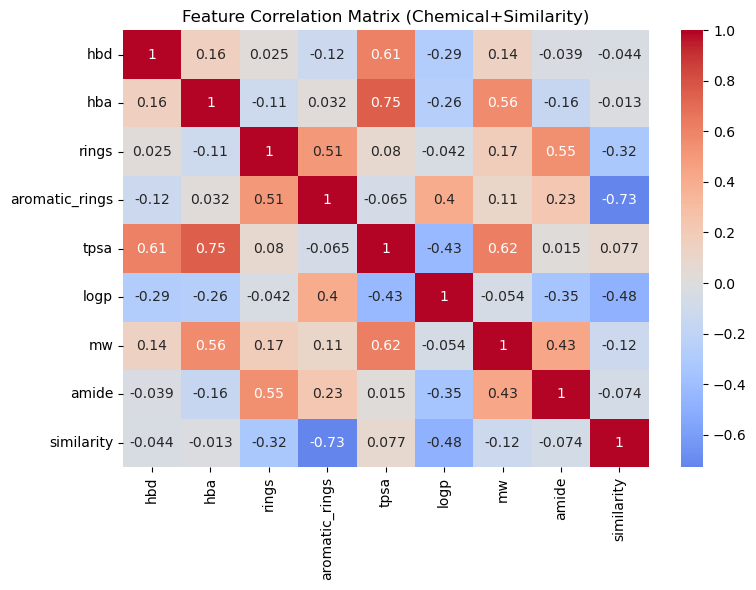

In [14]:
# P6.D-P6.H Variance, K-means diagnostics, and PCA visualization
import matplotlib.ticker as mtick

pca_full = PCA()
_ = pca_full.fit_transform(X_chemsim_scaled)
explained_var_full = pca_full.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var_full)

components = np.arange(1, len(explained_var_full) + 1)
plt.figure(figsize=(9, 5))
bars = plt.bar(components, explained_var_full, color="steelblue", alpha=0.9, label="Explained variance")
for bar, var in zip(bars, explained_var_full):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005, f"{var * 100:.1f}%", ha="center", va="bottom", fontsize=9)
plt.plot(components, cumulative_var, color="darkorange", marker="o", linewidth=2, label="Cumulative variance")
plt.axhline(config.BINDING_P6_PCA_CUMVAR_THRESHOLD, linestyle="--", color="crimson", label=f"{config.BINDING_P6_PCA_CUMVAR_THRESHOLD*100:.0f}% threshold")
plt.xticks(components)
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))
plt.xlabel("Principal Component")
plt.ylabel("Variance Explained")
plt.title("PCA Variance Explained by Component (Chemical+Similarity)")
plt.legend()
plt.tight_layout()
plt.savefig(plots_dir / "p6_pca_variance_explained.png", dpi=300, bbox_inches="tight")
plt.show()

k_range = config.BINDING_P6_K_RANGE
inertia_chemsim, silhouette_scores_chemsim = evaluate_k(X_chemsim_scaled, k_range)

plt.figure(figsize=(6, 4))
plt.plot(k_range, inertia_chemsim, marker="o")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.title("Elbow Method (Chemical+Similarity)")
plt.tight_layout()
plt.savefig(plots_dir / "p6_elbow_method.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(k_range, silhouette_scores_chemsim, marker="s")
plt.xlabel("k")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs k (Chemical+Similarity)")
plt.tight_layout()
plt.savefig(plots_dir / "p6_silhouette_vs_k.png", dpi=300, bbox_inches="tight")
plt.show()

from sklearn.metrics import silhouette_samples

labels_chemsim_k2 = binding_artifacts["labels_chemsim_k2"]
labels_chemsim_k4 = binding_artifacts["labels_chemsim_k4"]

sample_sil_chemsim_k2 = silhouette_samples(X_chemsim_scaled, labels_chemsim_k2)
plt.figure(figsize=(6, 4))
plt.hist(sample_sil_chemsim_k2, bins=30)
plt.xlabel("Silhouette value")
plt.ylabel("Frequency")
plt.title("Silhouette Distribution (k=2) (Chemical+Similarity)")
plt.tight_layout()
plt.savefig(plots_dir / "p6_silhouette_distribution_k2.png", dpi=300, bbox_inches="tight")
plt.show()

sample_sil_chemsim_k4 = silhouette_samples(X_chemsim_scaled, labels_chemsim_k4)
plt.figure(figsize=(6, 4))
plt.hist(sample_sil_chemsim_k4, bins=30)
plt.xlabel("Silhouette value")
plt.ylabel("Frequency")
plt.title("Silhouette Distribution (k=4) (Chemical+Similarity)")
plt.tight_layout()
plt.savefig(plots_dir / "p6_silhouette_distribution_k4.png", dpi=300, bbox_inches="tight")
plt.show()

plot_phase6_df = phase6_df.copy()
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True, constrained_layout=True)
axes[0].scatter(plot_phase6_df["PC1"], plot_phase6_df["PC2"], c=plot_phase6_df["cluster_k2_phase6"], alpha=0.60, cmap="viridis", s=20)
axes[0].set_title("K-Means (k=2) on PCA")
axes[0].set_xlabel(f"PC1 ({explained_var_chemsim[0]*100:.1f}% variance)")
axes[0].set_ylabel(f"PC2 ({explained_var_chemsim[1]*100:.1f}% variance)")

axes[1].scatter(plot_phase6_df["PC1"], plot_phase6_df["PC2"], c=plot_phase6_df["cluster_k4_phase6"], alpha=0.60, cmap="tab10", s=20)
axes[1].set_title("K-Means (k=4) on PCA")
axes[1].set_xlabel(f"PC1 ({explained_var_chemsim[0]*100:.1f}% variance)")
fig.savefig(plots_dir / "p6_kmeans_pca_k2_k4.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(X_chemsim_features.corr(), annot=True, cmap="coolwarm", center=0)
plt.title("Feature Correlation Matrix (Chemical+Similarity)")
plt.tight_layout()
plt.savefig(plots_dir / "p6_feature_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

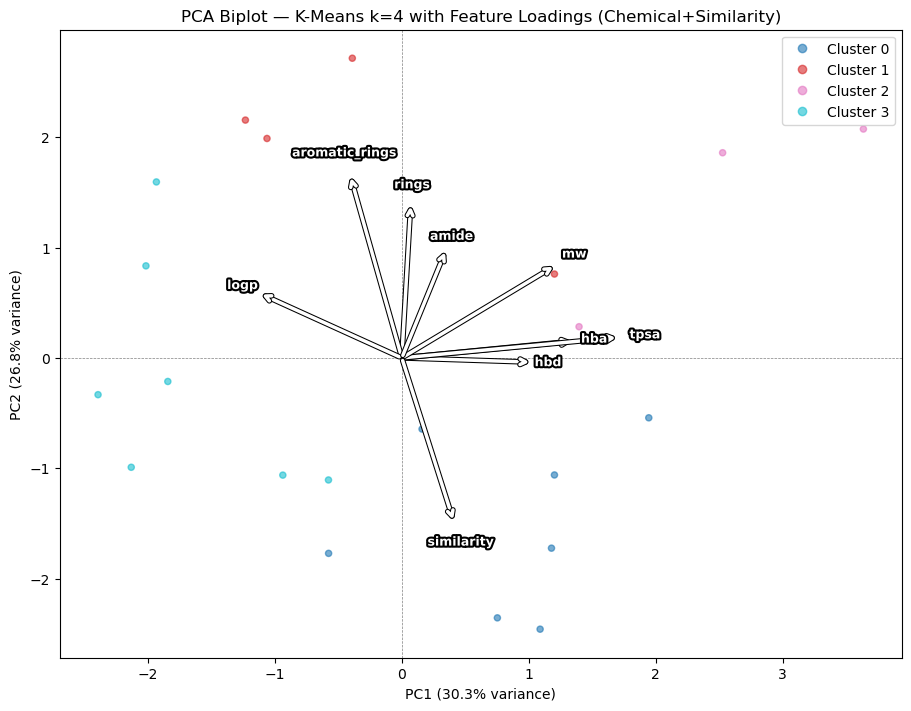

In [16]:
# P6.G PCA Loadings Biplot (chemistry + similarity)
# Feature loadings overlaid on k=4 cluster assignments.
import matplotlib.patheffects as pe

plot_phase6_df = phase6_df.copy()
arrow_scale = 3.0
feature_names = loadings_chemsim.index.tolist()

fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)

sc = ax.scatter(
    plot_phase6_df["PC1"],
    plot_phase6_df["PC2"],
    c=plot_phase6_df["cluster_k4_phase6"],
    alpha=0.60,
    cmap="tab10",
    s=20,
    zorder=1,
)

handles, _ = sc.legend_elements(prop="colors")
ax.legend(handles, [f"Cluster {k}" for k in range(4)], loc="best")

for feat in feature_names:
    dx = loadings_chemsim.loc[feat, "PC1"] * arrow_scale
    dy = loadings_chemsim.loc[feat, "PC2"] * arrow_scale

    ax.annotate(
        "",
        xy=(dx, dy),
        xytext=(0, 0),
        arrowprops=dict(
            arrowstyle="->",
            color="white",
            lw=2.5,
            path_effects=[pe.Stroke(linewidth=4, foreground="black"), pe.Normal()],
        ),
        zorder=4,
    )

    ax.text(
        dx * 1.12,
        dy * 1.12,
        feat,
        fontsize=9,
        fontweight="bold",
        color="white",
        ha="center",
        va="center",
        path_effects=[pe.Stroke(linewidth=3, foreground="black"), pe.Normal()],
        zorder=5,
    )

ax.axhline(0, color="grey", lw=0.5, ls="--")
ax.axvline(0, color="grey", lw=0.5, ls="--")
ax.set_xlabel(f"PC1 ({explained_var_chemsim[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({explained_var_chemsim[1]*100:.1f}% variance)")
ax.set_title("PCA Biplot — K-Means k=4 with Feature Loadings (Chemical+Similarity)")

plt.savefig(plots_dir / "p6_pca_loadings_biplot_k4.png", dpi=300, bbox_inches="tight")
plt.show()

/Users/alangale/miniconda3/envs/tfmac/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/alangale/miniconda3/envs/tfmac/lib/python3.10/site-packages/umap/umap_.py:2462: UserWarning: n_neighbors is larger than the dataset size; truncating to X.shape[0] - 1
  warn(


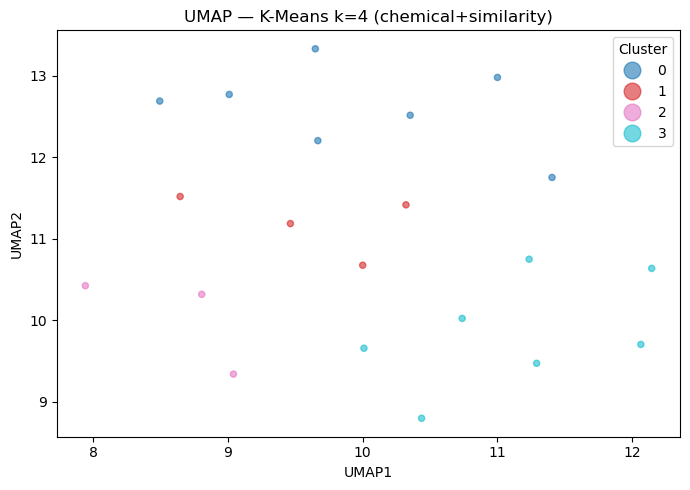

In [17]:
# P6.H UMAP clustering (chemistry + similarity)
import umap

umap_n_neighbors = getattr(config, "BINDING_P6_UMAP_N_NEIGHBORS", 50)
umap_min_dist = getattr(config, "BINDING_P6_UMAP_MIN_DIST", 0.5)

umap_chemsim_model = umap.UMAP(
    n_neighbors=umap_n_neighbors,
    min_dist=umap_min_dist,
    n_components=2,
    random_state=config.RANDOM_STATE,
)
X_chemsim_umap = umap_chemsim_model.fit_transform(X_chemsim_scaled)

fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(
    X_chemsim_umap[:, 0],
    X_chemsim_umap[:, 1],
    c=binding_artifacts["labels_chemsim_k4"],
    cmap="tab10",
    s=20,
    alpha=0.6,
)
ax.legend(*sc.legend_elements(), title="Cluster", markerscale=2)
ax.set_title("UMAP — K-Means k=4 (chemical+similarity)")
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
plt.tight_layout()
plt.savefig(plots_dir / "p6_umap_kmeans_k4.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# P7.A-P7.M Train baseline + regularized linear models
X_train_scaled = binding_artifacts["X_train_scaled"]
y_train = binding_artifacts["y_train"]
X_test_scaled = binding_artifacts["X_test_scaled"]
y_test = binding_artifacts["y_test"]
feature_cols_balr = binding_artifacts["feature_cols"]

alpha_grid = np.logspace(
    config.BINDING_P7_ALPHA_LOGSPACE_START,
    config.BINDING_P7_ALPHA_LOGSPACE_STOP,
    config.BINDING_P7_ALPHA_LOGSPACE_NUM,
)

baseline_result = train_baseline_regression(X_train_scaled, y_train, X_test_scaled, y_test)
elastic_result = train_elastic_net(
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test,
    alphas=alpha_grid,
    l1_ratios=config.BINDING_P7_ELASTIC_L1_RATIOS,
    random_state=config.RANDOM_STATE,
)
ridge_result = train_ridge(
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test,
    alphas=alpha_grid,
)
lasso_result = train_lasso(
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test,
    alphas=alpha_grid,
    random_state=config.RANDOM_STATE,
)

model_results = [baseline_result, elastic_result, ridge_result, lasso_result]

print("Baseline test metrics:", baseline_result["test_metrics"])
print("Elastic best alpha/l1:", elastic_result["best_alpha"], elastic_result["best_l1_ratio"])
print("Ridge best alpha:", ridge_result["best_alpha"])
print("Lasso best alpha:", lasso_result["best_alpha"])

,model,train_R2,test_R2,train_RMSE,test_RMSE,train_MAE,test_MAE
0,Baseline Linear Regression,0.785280,-0.111324,0.335074,0.643041,0.293902,0.564564
1,Elastic Net,0.602980,-0.297735,0.455629,0.694883,0.368460,0.581924
2,Ridge,0.741802,-0.806329,0.367435,0.819817,0.315229,0.703866
3,Lasso,0.593294,-0.330289,0.461153,0.703544,0.376670,0.622084


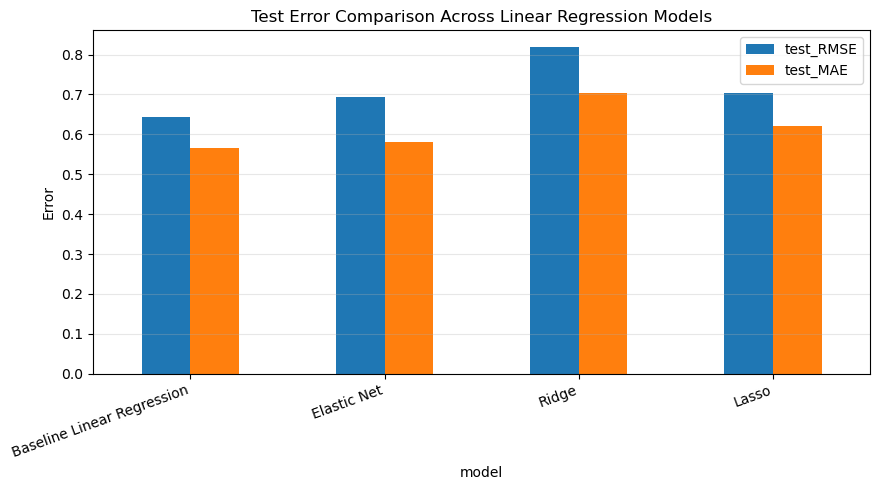

In [18]:
# P7.N Compare all models and visualize test errors
comparison_df_balr = compare_models(model_results)
display(comparison_df_balr)

metric_plot_df_balr = comparison_df_balr[["model", "test_RMSE", "test_MAE"]].set_index("model")
metric_plot_df_balr.plot(kind="bar", figsize=(9, 5))
plt.ylabel("Error")
plt.title("Test Error Comparison Across Linear Regression Models")
plt.xticks(rotation=20, ha="right")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(plots_dir / "p7_model_test_error_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

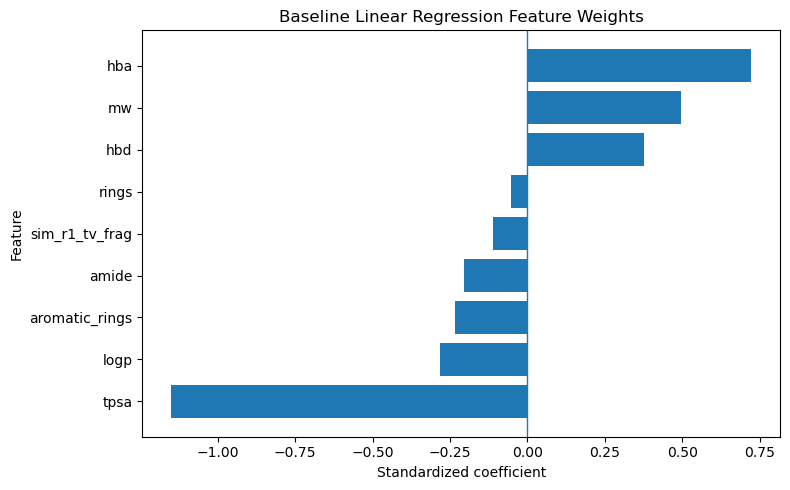

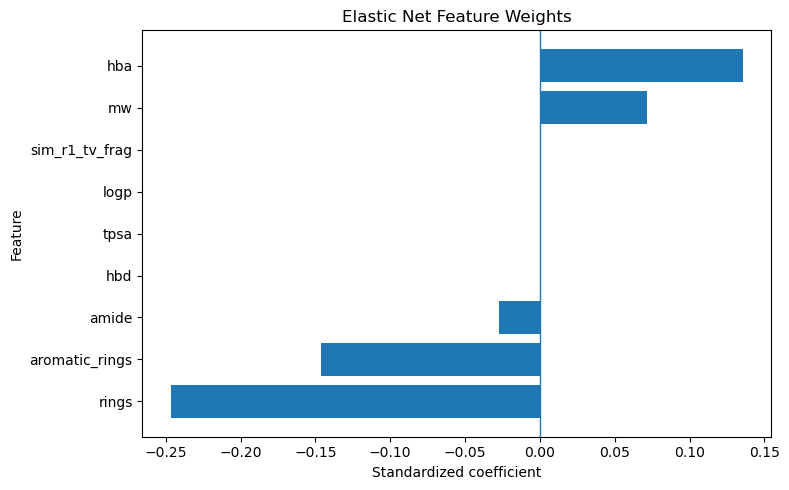

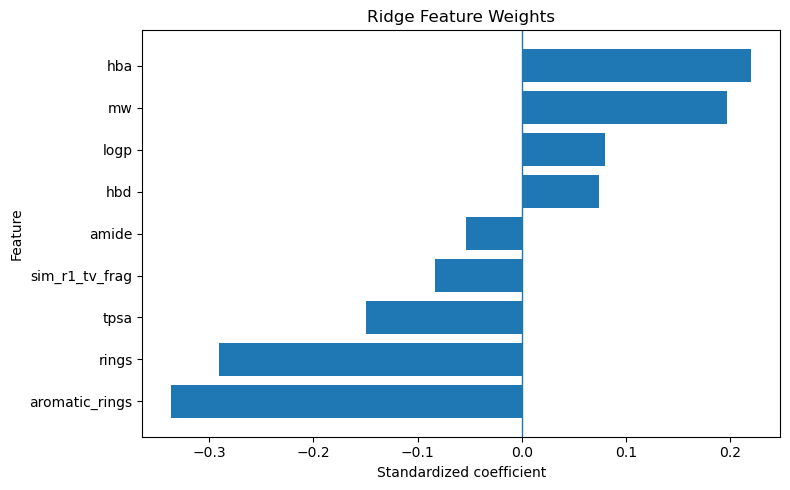

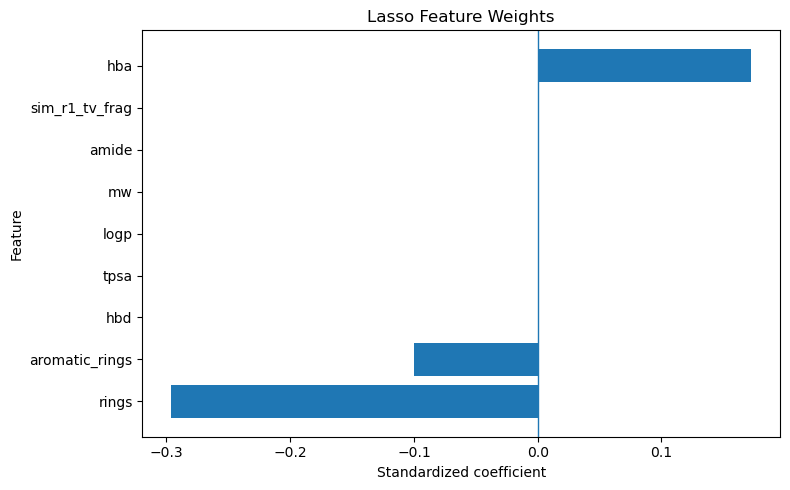

,feature,baseline,elastic_net,ridge,lasso
0,hbd,0.375679,-0.000000,0.074213,-0.000000
1,hba,0.721781,0.135426,0.220081,0.172388
2,rings,-0.051871,-0.246470,-0.290491,-0.296023
3,aromatic_rings,-0.232729,-0.146553,-0.336220,-0.100327
4,tpsa,-1.149545,-0.000000,-0.149722,-0.000000
5,logp,-0.282232,0.000000,0.080407,0.000000
6,mw,0.495573,0.071456,0.197276,0.000000
7,amide,-0.206247,-0.027365,-0.053767,-0.000000
8,sim_r1_tv_frag,-0.110708,-0.000000,-0.083219,-0.000000


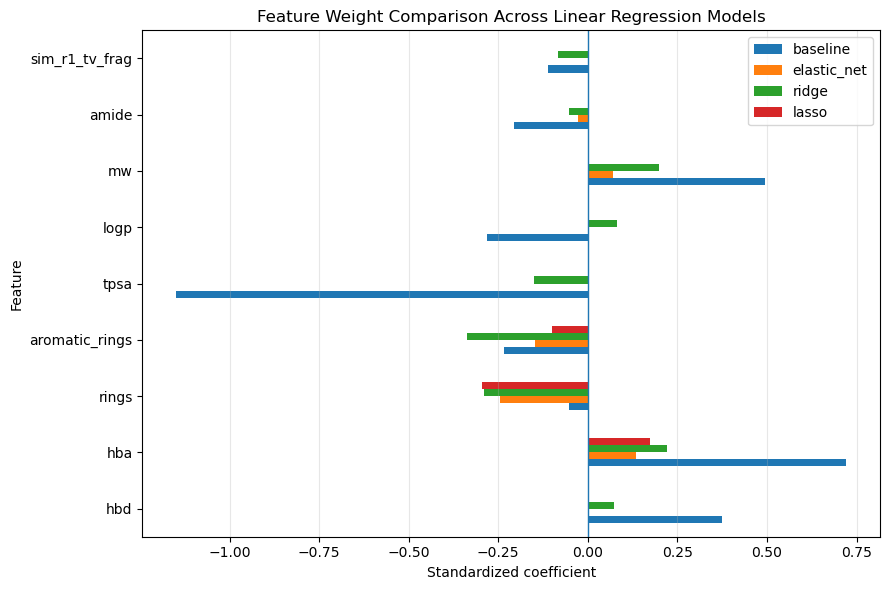

In [19]:
# P7.O Feature-importance tables and plots
coef_df_baseline = plot_feature_importance(
    baseline_result,
    feature_cols_balr,
    title="Baseline Linear Regression Feature Weights",
    output_path=plots_dir / "p7_feature_weights_baseline.png",
)
coef_df_elastic = plot_feature_importance(
    elastic_result,
    feature_cols_balr,
    title="Elastic Net Feature Weights",
    output_path=plots_dir / "p7_feature_weights_elastic_net.png",
)
coef_df_ridge = plot_feature_importance(
    ridge_result,
    feature_cols_balr,
    title="Ridge Feature Weights",
    output_path=plots_dir / "p7_feature_weights_ridge.png",
)
coef_df_lasso = plot_feature_importance(
    lasso_result,
    feature_cols_balr,
    title="Lasso Feature Weights",
    output_path=plots_dir / "p7_feature_weights_lasso.png",
)

coef_compare_df_balr = pd.DataFrame({
    "feature": feature_cols_balr,
    "baseline": baseline_result["model"].coef_,
    "elastic_net": elastic_result["model"].coef_,
    "ridge": ridge_result["model"].coef_,
    "lasso": lasso_result["model"].coef_,
})
display(coef_compare_df_balr)

coef_compare_plot_df_balr = coef_compare_df_balr.set_index("feature")
coef_compare_plot_df_balr.plot(kind="barh", figsize=(9, 6))
plt.axvline(0, linewidth=1)
plt.xlabel("Standardized coefficient")
plt.ylabel("Feature")
plt.title("Feature Weight Comparison Across Linear Regression Models")
plt.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(plots_dir / "p7_feature_weight_comparison_across_models.png", dpi=300, bbox_inches="tight")
plt.show()

,cluster_k2,quartile,n,mean_actual_vina,mean_predicted_vina,mean_residual,MAE,RMSE
0,0,0,1,-8.511,-8.059970,-0.451030,0.451030,0.451030
1,0,1,1,-8.275,-8.610030,0.335030,0.335030,0.335030
2,0,2,1,-7.581,-7.773630,0.192630,0.192630,0.192630
3,0,3,1,-9.150,-8.059672,-1.090328,1.090328,1.090328
4,1,0,1,-7.691,-7.986159,0.295159,0.295159,0.295159
5,1,1,1,-7.310,-8.155348,0.845348,0.845348,0.845348
6,1,2,1,-7.554,-8.296420,0.742420,0.742420,0.742420


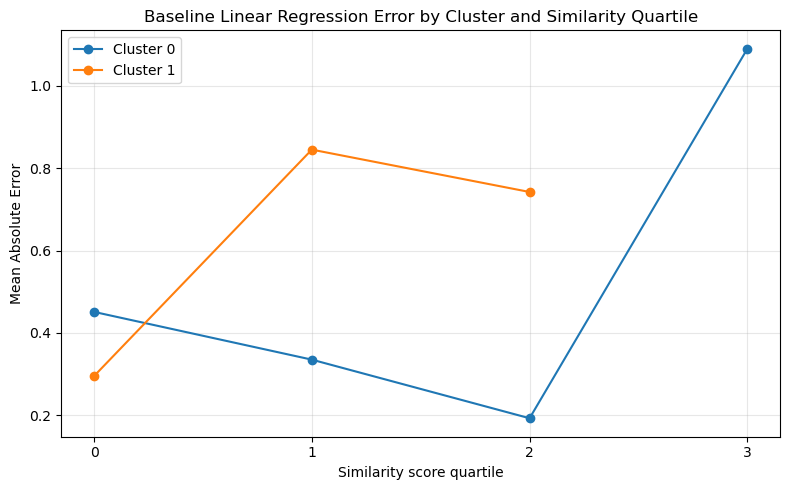

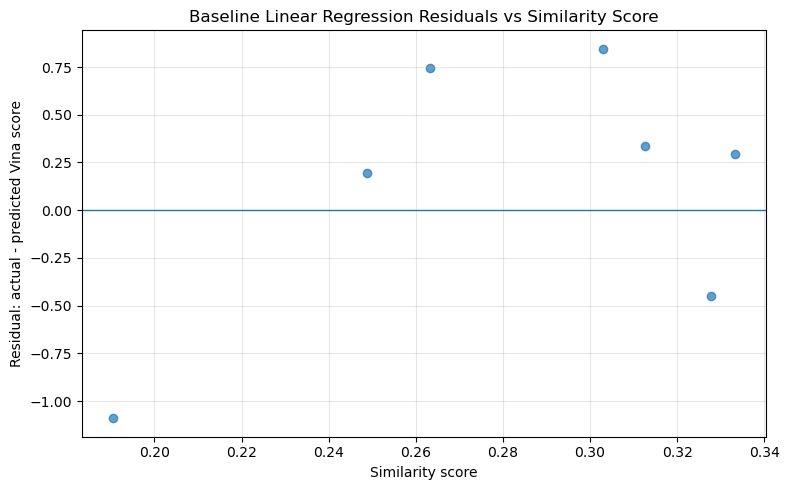

In [9]:
# P7.G Error analysis (baseline model)
err = error_analysis(
    binding_artifacts["test_df"],
    y_test,
    baseline_result["y_test_pred"],
    cluster_col="cluster_k2",
    quartile_col="quartile",
    similarity_col=binding_artifacts["similarity_col"],
)

quartile_error_df_balr = err["summary_df"]
baseline_eval_df_balr = err["eval_df"]
display(quartile_error_df_balr)

plt.figure(figsize=(8, 5))
for cluster_id in sorted(quartile_error_df_balr["cluster_k2"].unique()):
    cluster_data = quartile_error_df_balr[quartile_error_df_balr["cluster_k2"] == cluster_id]
    plt.plot(cluster_data["quartile"], cluster_data["MAE"], marker="o", label=f"Cluster {cluster_id}")
plt.xlabel("Similarity score quartile")
plt.ylabel("Mean Absolute Error")
plt.title("Baseline Linear Regression Error by Cluster and Similarity Quartile")
plt.xticks(sorted(quartile_error_df_balr["quartile"].unique()))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(plots_dir / "p7_baseline_mae_by_cluster_quartile.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(
    baseline_eval_df_balr[binding_artifacts["similarity_col"]],
    baseline_eval_df_balr["residual"],
    alpha=0.7,
)
plt.axhline(0, linewidth=1)
plt.xlabel("Similarity score")
plt.ylabel("Residual: actual - predicted Vina score")
plt.title("Baseline Linear Regression Residuals vs Similarity Score")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(plots_dir / "p7_baseline_residuals_vs_similarity.png", dpi=300, bbox_inches="tight")
plt.show()

In [20]:
# Save model comparison and coefficient tables
comparison_csv = results_dir / "binding_model_comparison.csv"
coef_baseline_csv = results_dir / "binding_coef_baseline.csv"
coef_elastic_csv = results_dir / "binding_coef_elastic_net.csv"
coef_ridge_csv = results_dir / "binding_coef_ridge.csv"
coef_lasso_csv = results_dir / "binding_coef_lasso.csv"
coef_compare_csv = results_dir / "binding_coef_model_comparison.csv"

comparison_df_balr.to_csv(comparison_csv, index=False)
coef_df_baseline.to_csv(coef_baseline_csv, index=False)
coef_df_elastic.to_csv(coef_elastic_csv, index=False)
coef_df_ridge.to_csv(coef_ridge_csv, index=False)
coef_df_lasso.to_csv(coef_lasso_csv, index=False)
coef_compare_df_balr.to_csv(coef_compare_csv, index=False)

saved_plot_paths = sorted(plots_dir.glob("*.png"))

print("Saved tables:")
print("-", comparison_csv)
print("-", coef_baseline_csv)
print("-", coef_elastic_csv)
print("-", coef_ridge_csv)
print("-", coef_lasso_csv)
print("-", coef_compare_csv)

print("\nSaved plots:")
for p in saved_plot_paths:
    print("-", p)

Saved tables:
- /Users/alangale/Projects/rapalog-discovery-pipeline/results/notebook_06/debug/binding_model_comparison.csv
- /Users/alangale/Projects/rapalog-discovery-pipeline/results/notebook_06/debug/binding_coef_baseline.csv
- /Users/alangale/Projects/rapalog-discovery-pipeline/results/notebook_06/debug/binding_coef_elastic_net.csv
- /Users/alangale/Projects/rapalog-discovery-pipeline/results/notebook_06/debug/binding_coef_ridge.csv
- /Users/alangale/Projects/rapalog-discovery-pipeline/results/notebook_06/debug/binding_coef_lasso.csv
- /Users/alangale/Projects/rapalog-discovery-pipeline/results/notebook_06/debug/binding_coef_model_comparison.csv

Saved plots:
- /Users/alangale/Projects/rapalog-discovery-pipeline/results/notebook_06/debug/plots/p6_elbow_method.png
- /Users/alangale/Projects/rapalog-discovery-pipeline/results/notebook_06/debug/plots/p6_feature_correlation_heatmap.png
- /Users/alangale/Projects/rapalog-discovery-pipeline/results/notebook_06/debug/plots/p6_kmeans_pca_k